In [2]:
import pandas as pd
import numpy as np
from openpyxl import load_workbook
import pandas as pd
import matplotlib.pyplot as plt 
import matplotlib
from sklearn.model_selection import train_test_split,GridSearchCV, KFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_squared_error as MSE

In [3]:
books = pd.read_csv("finetune_data.csv")
books

,FP (K),MolWt,ExactMolWt,HeavyAtomMolWt,LabuteASA,Chi0,HeavyAtomCount,Chi1,BCUT2D_CHGHI,NumValenceElectrons,...,fr_thiocyan,fr_isothiocyan,EState_VSA11,fr_azide,fr_barbitur,fr_alkyl_carbamate,fr_quatN,SOURCE,smiles,type
0,250.15,86.178,86.10955,72.066,40.56396,4.828427,6,2.914214,1.748868,38,...,0,0,0,0,0,0,0,Sheet15,CCCCCC,1
1,269.00,100.205,100.12520,84.077,46.92890,5.535534,7,3.414214,1.796207,44,...,0,0,0,0,0,0,0,Sheet15,CCCCCCC,2
2,263.15,100.205,100.12520,84.077,46.92890,5.698671,7,3.270056,1.882188,44,...,0,0,0,0,0,0,0,Sheet15,CCCCC(C)C,3
3,287.15,114.232,114.14090,96.088,53.29385,6.242641,8,3.914214,1.829101,50,...,0,0,0,0,0,0,0,Sheet15,CCCCCCCC,4
4,279.15,114.232,114.14090,96.088,53.29385,6.405777,8,3.770056,1.901122,50,...,0,0,0,0,0,0,0,Sheet15,CCCCCC(C)C,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
730,383.00,176.256,176.14120,156.096,74.68011,9.071068,12,5.914214,1.885462,74,...,0,0,0,0,0,0,0,Sheet15,CCCCCOCCOCCO,731
731,373.55,190.283,190.15690,168.107,81.04505,10.104450,13,6.201907,2.046425,80,...,0,0,0,0,0,0,0,Sheet15,CCCCOC(C)COC(C)CO,732
732,304.15,115.176,115.09970,102.072,50.43151,5.819991,8,3.931852,2.052398,48,...,0,0,0,0,0,0,0,Sheet15,CCN1CCOCC1,733
733,333.15,120.173,120.02450,112.109,48.26421,5.698671,7,3.308060,1.926854,42,...,0,0,0,0,0,0,0,Sheet15,COC(=O)CCS,734


In [4]:
list_feature_rf = ['Ipc', 'HeavyAtomMolWt', 'TPSA', 'VSA_EState3', 'AvgIpc', 'Chi1', 'VSA_EState8', 'BertzCT', 'HallKierAlpha', 'BCUT2D_MRHI', 'ExactMolWt', 'EState_VSA2', 'qed', 'MolLogP', 'Chi4v', 'MolWt', 'LabuteASA', 'Chi3v', 'MaxAbsEStateIndex', 'NumHDonors', 'MaxPartialCharge']
x = books[list_feature_rf]
x

,Ipc,HeavyAtomMolWt,TPSA,VSA_EState3,AvgIpc,Chi1,VSA_EState8,BertzCT,HallKierAlpha,BCUT2D_MRHI,...,EState_VSA2,qed,MolLogP,Chi4v,MolWt,LabuteASA,Chi3v,MaxAbsEStateIndex,NumHDonors,MaxPartialCharge
0,20.98630,72.066,0.00,0.000000,1.614331,2.914214,4.463611,12.00000,0.00,4.307622,...,0.000000,0.462954,2.5866,0.500000,86.178,40.56396,0.957107,2.231806,0,-0.053580
1,35.50961,84.077,0.00,0.000000,1.690934,3.414214,4.491389,19.21928,0.00,4.354233,...,0.000000,0.476310,2.9767,0.676777,100.205,46.92890,1.207107,2.245694,0,-0.053330
2,29.01955,84.077,0.00,0.000000,1.612197,3.270056,6.785417,29.01955,0.00,4.417096,...,0.000000,0.511270,2.8326,0.612372,100.205,46.92890,1.135028,2.273472,0,-0.047130
3,61.49961,96.088,0.00,0.000000,1.808812,3.914214,4.511797,25.01955,0.00,4.386659,...,0.000000,0.480611,3.3668,0.853553,114.232,53.29385,1.457107,2.255899,0,-0.053320
4,48.27551,96.088,0.00,0.000000,1.664673,3.770056,6.825046,37.30297,0.00,4.438797,...,0.000000,0.492147,3.2227,0.802586,114.232,53.29385,1.385028,2.287361,0,-0.047130
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
730,488.92510,156.096,38.69,8.373106,2.098391,5.914214,4.741308,66.17390,-0.12,4.362655,...,6.606882,0.536466,1.2021,0.840649,176.256,74.68011,1.499862,8.373106,1,0.070112
731,660.13770,168.107,38.69,8.695977,2.143304,6.201907,7.401322,106.34300,-0.12,4.508217,...,18.814810,0.590656,1.5890,0.829448,190.283,81.04505,1.772821,8.695977,1,0.078009
732,91.36758,102.072,12.47,0.000000,1.903491,3.931852,7.447778,59.54888,-0.08,4.573167,...,0.000000,0.488308,0.3385,0.917392,115.176,50.43151,1.550918,5.159861,0,0.059362
733,31.91664,112.109,26.30,0.000000,1.679823,3.308060,0.000000,62.71013,-0.18,7.797711,...,5.969305,0.423496,0.4793,0.375923,120.173,48.26421,0.767205,10.140690,1,0.305832


In [5]:
y = books['FP (K)']

In [9]:
param_grid = {
    # 'max_depth': range(6,16),
    'n_estimators': range(50, 601, 50),
    # 'min_samples_split':range(2,8)
}

# 外循环：10折交叉验证
kf = KFold(n_splits=5, shuffle=True, random_state=42)
list_best_params = []
for train_index, test_index in kf.split(x):
    # 根据索引分割数据
    x_train, x_test = x.iloc[train_index], x.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]
    
    from sklearn.preprocessing import StandardScaler
    # 创建标准化器，并在训练集上拟合
    scaler_x = StandardScaler()
    scaler_feature = scaler_x.fit(x_train)
    
    # 使用相同的标准化器转换训练集和测试集
    x_train_std = scaler_feature.transform(x_train)
    x_test_std = scaler_feature.transform(x_test)
    
    # 内循环：在训练集上进行10折交叉验证调整超参数
    best_score = -np.inf
    best_params = {}

    # 遍历超参数网格
    for n_estimators in param_grid['n_estimators']:
        # for max_depth in param_grid['max_depth']:
        #     for min_samples_split in param_grid['min_samples_split']:
                # 设置当前的超参数组合
        params = {
            'n_estimators': n_estimators,
            # 'max_depth': max_depth,
            # 'min_samples_split': min_samples_split,
        }

        # 初始化随机森林模型
        model = RandomForestRegressor(**params)

        # 使用cross_val_score进行10折交叉验证
        cv_scores = cross_val_score(model, x_train_std, y_train, cv=5, scoring='r2')

        # 计算平均R2分数
        mean_score = np.mean(cv_scores)

        # 记录最佳参数组合
        if mean_score > best_score:
            best_score = mean_score
            best_params = params

    print(f"Test fold {test_index + 1}:")
    print(f"best_score {best_score}:")
    print(f"Best hyperparameters: {best_params}")
    list_best_params.append(best_params)
    
    # 使用最佳参数训练模型
    model = RandomForestRegressor(**best_params)
    model.fit(x_train_std, y_train)
    
    # 在测试集上评估模型
    predictions = model.predict(x_test_std)
    test_score = r2_score(y_test, predictions)
    test_MSE = MSE(y_test, predictions)
    print(f"Test R2 score: {test_score}")
    print(f"Test MSE: {test_MSE}")

Test fold [  3  11  24  31  32  34  40  45  50  55  56  61  64  66  67  70  71  73
  77  78  79  80  82  85  87  91  98 102 110 119 121 132 134 149 156 159
 166 175 182 193 197 199 200 211 212 214 216 224 232 235 240 245 248 249
 251 261 266 267 276 282 287 292 300 307 312 324 325 329 330 332 334 335
 337 339 341 347 351 352 356 358 361 364 368 372 376 378 397 399 417 421
 423 424 430 449 450 454 465 468 469 470 487 514 517 518 527 533 540 542
 545 546 560 569 576 577 587 591 600 602 606 609 610 611 619 629 632 638
 642 655 659 666 667 670 672 675 676 680 683 696 697 702 714 716 719 722
 731 732 734]:
best_score 0.8322985518848294:
Best hyperparameters: {'n_estimators': 400}
Test R2 score: 0.871425369516303
Test MSE: 300.1267119085683
Test fold [  7   8  10  12  16  19  23  25  29  30  42  43  44  52  57  62  74  83
  84  90  93  94 105 109 111 115 133 136 137 138 140 141 146 164 165 168
 177 178 179 183 185 204 205 209 210 213 219 221 222 228 236 250 255 257
 258 260 265 285 291 293 2

In [10]:
list_best_params = [{'n_estimators': 400},
 {'n_estimators': 250},
 {'n_estimators': 50},
 {'n_estimators': 350},
 {'n_estimators': 550}]

Train
Average R2 Score: 0.9851
Average RMSE: 6.5223
Average MAE: 4.4121
Test
Average R2 Score: 0.8882
Average RMSE: 17.8862
Average MAE: 12.1276


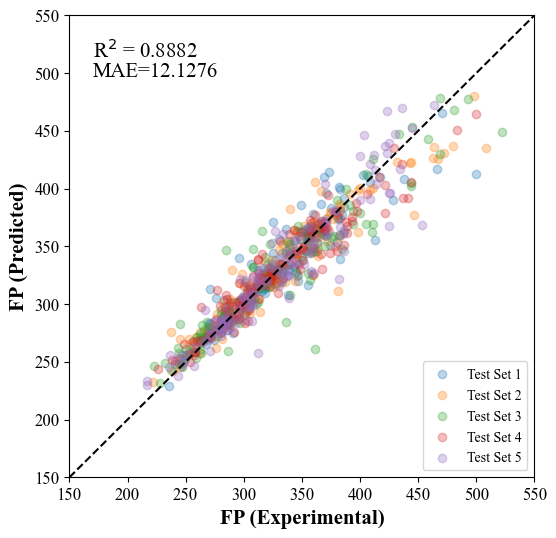

In [16]:
list_train_predictions = []
list_train_y = []
list_test_predictions = []
list_test_y = []
i = 0
from sklearn.preprocessing import StandardScaler
kf = KFold(n_splits=5, shuffle=True, random_state=42)
Train_r2 = []
Train_MAE = []
Test_r2 = []
Test_MAE = []
for train_index, test_index in kf.split(x):
    # 根据索引分割数据
    x_train, x_test = x.iloc[train_index], x.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]
    
    # 创建标准化器，并在训练集上拟合
    scaler_x = StandardScaler()
    scaler_feature = scaler_x.fit(x_train)
    
    # 使用相同的标准化器转换训练集和测试集
    x_train_std = scaler_feature.transform(x_train)
    x_test_std = scaler_feature.transform(x_test)
    
    params = list_best_params[i]

    model = RandomForestRegressor(**params)
    model.fit(x_train_std, y_train)

    predictions_train = model.predict(x_train_std)

    list_train_predictions.append(predictions_train.tolist())
    list_train_y.append(y_train)

    # 在测试集上评估模型
    predictions_test = model.predict(x_test_std)
    
    list_test_predictions.append(predictions_test.tolist())
    list_test_y.append(y_test)
    
    i = i+1
# 将收集的结果转换为numpy数组
list_train_predictions_one = [item for sublist in list_train_predictions for item in sublist]
list_train_y_one = [item for sublist in list_train_y for item in sublist]

list_test_predictions_one = [item for sublist in list_test_predictions for item in sublist]
list_test_y_one = [item for sublist in list_test_y for item in sublist]

# 计算R²分数的平均值
train_r2 = r2_score(list_train_y_one, list_train_predictions_one)
train_rmse = np.sqrt(mean_squared_error(list_train_y_one, list_train_predictions_one))
train_mae = mean_absolute_error(list_train_y_one, list_train_predictions_one)

print("Train")
print(f"Average R2 Score: {train_r2:.4f}")
print(f"Average RMSE: {train_rmse:.4f}")
print(f"Average MAE: {train_mae:.4f}")

test_r2 = r2_score(list_test_y_one, list_test_predictions_one)
test_rmse = np.sqrt(mean_squared_error(list_test_y_one, list_test_predictions_one))
test_mae = mean_absolute_error(list_test_y_one, list_test_predictions_one)

print("Test")
print(f"Average R2 Score: {test_r2:.4f}")
print(f"Average RMSE: {test_rmse:.4f}")
print(f"Average MAE: {test_mae:.4f}")

formatted_score = f"{test_r2:.4f}"
formatted_MAE = f"{test_mae:.4f}"

matplotlib.rcParams['font.family'] = 'Times New Roman'
# 绘制散点图和对角线
plt.figure(figsize=(6, 6))
for i, (exp, preds) in enumerate(zip(list_test_y, list_test_predictions)):
    plt.scatter(exp, preds, alpha=0.3
                , label=f'Test Set {i+1}'
               )

plt.plot([150, 550], [150, 550], 'k--')  # 绘制对角线
plt.xlabel('FP (Experimental)', fontsize=15, fontweight='bold')
plt.ylabel('FP (Predicted)', fontsize=15, fontweight='bold')
plt.annotate(f'R$^2$ = {formatted_score}', xy=(1, 1), xycoords='axes fraction',
             xytext=(0.05, 0.95), textcoords='axes fraction',
             fontsize=15, ha='left', va='top', color='black')
plt.annotate(f'MAE={formatted_MAE}', xy=(1, 0.95), xycoords='axes fraction',
             xytext=(0.05, 0.9), textcoords='axes fraction',
             fontsize=15, ha='left', va='top', color='black')

# 添加图例
plt.legend(loc='lower right')
plt.xlim(150, 550)
plt.ylim(150, 550)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.show()

In [18]:
predict_df = pd.DataFrame({'FP': list_test_y_one, 'predict': list_test_predictions_one})
predict_df
from pandas import ExcelWriter

with ExcelWriter('FP-RF.xlsx') as writer:       
    predict_df.to_excel(writer,sheet_name='RF')